# MovieLens-20M — Exploratory Data Analysis

**Project:** ShopSage Recommender (Two-Tower retriever + LightGBM ranker)
**Day 1 goal:** understand the raw data well enough to make the modelling decisions that follow
(implicit-feedback threshold, filtering, negative sampling, evaluation split), then materialise the
leave-one-out split as parquet.

Everything here is **Polars** (no pandas) with **DuckDB** for a few analytical SQL queries. The
heavy lifting (loading, filtering, splitting) lives in `src/shopsage_rec/data/` so the notebook and
the CLI (`shopsage prepare`) share one code path.

Outputs:

| Artifact | Path |
|---|---|
| Plot 1 — rating distribution | `docs/figures/01_rating_distribution.png` |
| Plot 2 — ratings per user | `docs/figures/02_user_activity.png` |
| Plot 3 — item popularity long tail | `docs/figures/03_item_popularity_longtail.png` |
| Plot 4 (bonus) — genre volume | `docs/figures/04_genre_distribution.png` |
| Train / val / test splits | `data/processed/splits/{train,val,test}.parquet` + `meta.json` |

Run with `make eda` (executes in place via nbconvert) or interactively from the repo root.

In [1]:
from __future__ import annotations

import json
import time
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from shopsage_rec.config import load_data_config
from shopsage_rec.data.loader import load_movies, load_ratings, load_tags
from shopsage_rec.data.pipeline import run_prepare
from shopsage_rec.data.preprocess import parse_movies

ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
assert (ROOT / "pyproject.toml").exists(), "run from the repo root or from notebooks/"
CONFIG = ROOT / "configs" / "data" / "movielens_20m.yaml"
FIG_DIR = ROOT / "docs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

cfg = load_data_config(CONFIG, root=ROOT)
RAW = cfg.raw_dir
print(f"repo root : {ROOT}")
print(f"raw data  : {RAW}")
print(f"polars {pl.__version__} | duckdb {duckdb.__version__} | numpy {np.__version__}")

# ---- plot style: one accent hue, neutral ink, recessive grid (see dataviz conventions) ----
C = {
    "blue": "#2a78d6",   # series 1 / emphasis
    "orange": "#eb6834", # series 2 / reference marks
    "aqua": "#1baf7a",   # series 3
    "gray": "#b8b7b1",   # de-emphasis
    "ink": "#0b0b0b",
    "ink2": "#52514e",
    "grid": "#e6e5e1",
    "surface": "#fcfcfb",
}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160,
    "figure.facecolor": C["surface"], "axes.facecolor": C["surface"], "savefig.facecolor": C["surface"],
    "axes.edgecolor": C["grid"], "axes.labelcolor": C["ink2"],
    "axes.titlecolor": C["ink"], "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlesize": 12,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": C["grid"], "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": C["ink2"], "ytick.color": C["ink2"], "xtick.labelsize": 9, "ytick.labelsize": 9,
    "font.size": 10, "legend.frameon": False,
})
pl.Config.set_tbl_rows(20)
pl.Config.set_fmt_str_lengths(60)

repo root : /Users/zy/Project/new_sys/projects/shopsage-recommender
raw data  : /Users/zy/Project/new_sys/projects/shopsage-recommender/data/raw/ml-20m
polars 2.0.0 | duckdb 1.5.6 | numpy 2.5.4


polars.config.Config

## 1. Load the raw CSVs

`ratings.csv` is 533 MB on disk; Polars reads it in a few seconds and keeps it around 400 MB in
memory thanks to the pinned dtypes (`Int32` ids, `Float32` rating, `Int64` timestamp).

In [2]:
t0 = time.perf_counter()
ratings = load_ratings(RAW)
movies = parse_movies(load_movies(RAW))
tags = load_tags(RAW)
print(f"loaded in {time.perf_counter() - t0:.1f}s")
for name, df in [("ratings", ratings), ("movies", movies), ("tags", tags)]:
    print(f"{name:<8} {df.height:>12,} rows  {df.estimated_size('mb'):>8.1f} MB  {dict(df.schema)}")
ratings.head(5)

loaded in 0.7s
ratings    20,000,263 rows     381.5 MB  {'userId': Int32, 'movieId': Int32, 'rating': Float32, 'timestamp': Int64}
movies         27,278 rows       2.0 MB  {'movieId': Int32, 'title': String, 'title_clean': String, 'year': Int32, 'genres': List(String)}
tags          465,564 rows      12.0 MB  {'userId': Int32, 'movieId': Int32, 'tag': String, 'timestamp': Int64}


userId,movieId,rating,timestamp
i32,i32,f32,i64
1,2,3.5,1112486027
1,29,3.5,1112484676
1,32,3.5,1112484819
1,47,3.5,1112484727
1,50,3.5,1112484580


In [3]:
movies.head(5)

movieId,title,title_clean,year,genres
i32,str,str,i32,list[str]
1,"""Toy Story (1995)""","""Toy Story""",1995,"[""Adventure"", ""Animation"", … ""Fantasy""]"
2,"""Jumanji (1995)""","""Jumanji""",1995,"[""Adventure"", ""Children"", ""Fantasy""]"
3,"""Grumpier Old Men (1995)""","""Grumpier Old Men""",1995,"[""Comedy"", ""Romance""]"
4,"""Waiting to Exhale (1995)""","""Waiting to Exhale""",1995,"[""Comedy"", ""Drama"", ""Romance""]"
5,"""Father of the Bride Part II (1995)""","""Father of the Bride Part II""",1995,"[""Comedy""]"


## 2. Basic statistics: users, items, sparsity

"Sparsity" here is `1 - |ratings| / (|users| x |movies-with-ratings|)`. Every ML-20M user has at
least 20 ratings by construction (GroupLens filtered the sample that way), so the user side is
never cold — but the item side has a very long tail (section 4).

In [4]:
n_users = ratings["userId"].n_unique()
n_items_rated = ratings["movieId"].n_unique()
n_ratings = ratings.height
density = n_ratings / (n_users * n_items_rated)

ts = ratings["timestamp"]
t_min = pl.from_epoch(pl.Series([ts.min()]), time_unit="s")[0]
t_max = pl.from_epoch(pl.Series([ts.max()]), time_unit="s")[0]

per_user = ratings.group_by("userId").len().rename({"len": "n"})
per_item = ratings.group_by("movieId").len().rename({"len": "n"})

def quantiles(s: pl.Series) -> dict[str, float]:
    return {
        "min": s.min(), "p25": s.quantile(0.25), "median": s.median(), "mean": round(s.mean(), 1),
        "p75": s.quantile(0.75), "p90": s.quantile(0.90), "p99": s.quantile(0.99), "max": s.max(),
    }

summary = pl.DataFrame(
    {
        "metric": [
            "users", "movies (in movies.csv)", "movies with >= 1 rating", "ratings", "tag applications",
            "unique tags", "density", "sparsity", "first rating", "last rating",
        ],
        "value": [
            f"{n_users:,}", f"{movies.height:,}", f"{n_items_rated:,}", f"{n_ratings:,}", f"{tags.height:,}",
            f"{tags['tag'].n_unique():,}", f"{density:.4%}", f"{1 - density:.4%}", str(t_min.date()), str(t_max.date()),
        ],
    }
)
print(summary)
print()
print("ratings per user :", quantiles(per_user["n"]))
print("ratings per movie:", quantiles(per_item["n"]))

shape: (10, 2)
┌─────────────────────────┬────────────┐
│ metric                  ┆ value      │
│ ---                     ┆ ---        │
│ str                     ┆ str        │
╞═════════════════════════╪════════════╡
│ users                   ┆ 138,493    │
│ movies (in movies.csv)  ┆ 27,278     │
│ movies with >= 1 rating ┆ 26,744     │
│ ratings                 ┆ 20,000,263 │
│ tag applications        ┆ 465,564    │
│ unique tags             ┆ 38,644     │
│ density                 ┆ 0.5400%    │
│ sparsity                ┆ 99.4600%   │
│ first rating            ┆ 1995-01-09 │
│ last rating             ┆ 2015-03-31 │
└─────────────────────────┴────────────┘

ratings per user : {'min': 20, 'p25': 35.0, 'median': 68.0, 'mean': 144.4, 'p75': 155.0, 'p90': 334.0, 'p99': 1113.0, 'max': 9254}
ratings per movie: {'min': 1, 'p25': 3.0, 'median': 18.0, 'mean': 747.8, 'p75': 205.0, 'p90': 1306.0, 'p99': 14396.0, 'max': 67310}


## 3. Rating values (Plot 1)

Half-star ratings were introduced in 2003, so 0.5-step values are rarer than whole stars. The
project binarises feedback at **rating >= 4.0** (the Liang et al. 2018 ML-20M convention); the
chart emphasises exactly that cut, and the share it keeps is the first number that matters for
modelling (it sets the size of the positive set).

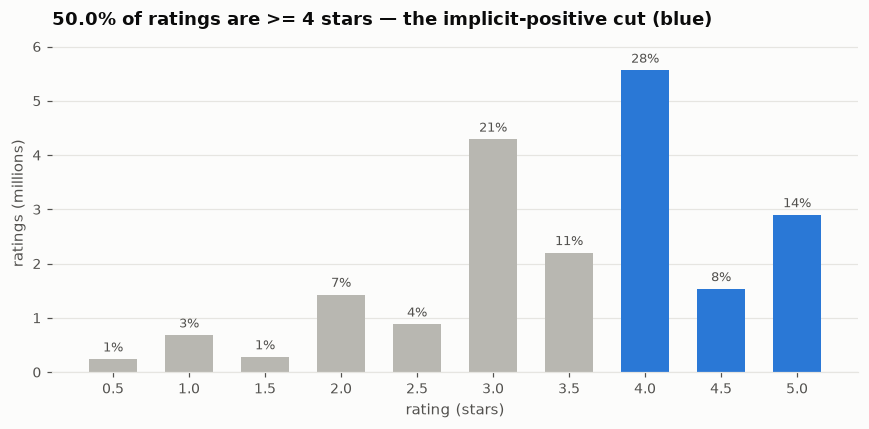

rating,n,share
f32,u32,f64
0.5,239125,0.011956
1.0,680732,0.034036
1.5,279252,0.013962
2.0,1430997,0.071549
2.5,883398,0.044169
3.0,4291193,0.214557
3.5,2200156,0.110006
4.0,5561926,0.278093
4.5,1534824,0.07674


In [5]:
rating_counts = (
    ratings.group_by("rating").len().rename({"len": "n"}).sort("rating")
    .with_columns((pl.col("n") / pl.col("n").sum()).alias("share"))
)
positive_share = rating_counts.filter(pl.col("rating") >= cfg.min_rating)["share"].sum()

fig, ax = plt.subplots(figsize=(8, 4))
colors = [C["blue"] if r >= cfg.min_rating else C["gray"] for r in rating_counts["rating"]]
bars = ax.bar(rating_counts["rating"], rating_counts["n"] / 1e6, width=0.32, color=colors, linewidth=0)
for bar, share in zip(bars, rating_counts["share"], strict=True):
    ax.annotate(f"{share:.0%}" if share >= 0.01 else f"{share:.1%}",
                (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=8.5, color=C["ink2"])
ax.set_xticks(rating_counts["rating"].to_list())
ax.set_xlabel("rating (stars)")
ax.set_ylabel("ratings (millions)")
ax.set_title(f"{positive_share:.1%} of ratings are >= {cfg.min_rating:g} stars — the implicit-positive cut (blue)")
ax.margins(y=0.12)
fig.tight_layout()
fig.savefig(FIG_DIR / "01_rating_distribution.png", bbox_inches="tight")
plt.show()
rating_counts

## 4. User activity (Plot 2)

How many ratings does a typical user have? This drives the choice of `min_user_interactions`, the
batch composition for in-batch negatives (heavy users dominate uniformly-sampled batches) and the
visitor's "pick 5 movies" profile panel in the demo (D-003: no per-user MovieLens rows ship).

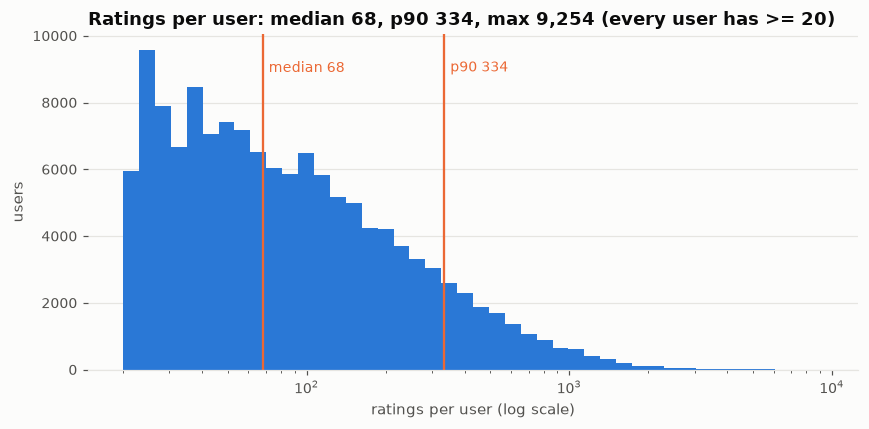

In [6]:
n = per_user["n"].to_numpy()
median_u, p90_u, max_u = np.median(n), np.quantile(n, 0.9), n.max()
bins = np.logspace(np.log10(n.min()), np.log10(n.max()), 45)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(n, bins=bins, color=C["blue"], linewidth=0)
ax.set_xscale("log")
for x, label in [(median_u, f"median {median_u:,.0f}"), (p90_u, f"p90 {p90_u:,.0f}")]:
    ax.axvline(x, color=C["orange"], linewidth=1.5)
    ax.annotate(label, (x, ax.get_ylim()[1] * 0.92), xytext=(4, 0), textcoords="offset points",
                color=C["orange"], fontsize=9, va="top")
ax.set_xlabel("ratings per user (log scale)")
ax.set_ylabel("users")
ax.set_title(f"Ratings per user: median {median_u:,.0f}, p90 {p90_u:,.0f}, max {max_u:,} (every user has >= {n.min()})")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_user_activity.png", bbox_inches="tight")
plt.show()

## 5. Item popularity: the long tail (Plot 3)

Two views of the same distribution: the rank-frequency curve on log-log axes (a straight-ish line
means power-law-like decay) and the cumulative share of ratings covered by the top-k% of movies.
The Gini coefficient summarises the inequality in one number.

Why it matters: a retriever trained with in-batch negatives mostly sees popular items as
negatives (they appear in batches more often — the classic sampling bias). Day 5's hard-negative
round adds **popularity-weighted sampled negatives** and the logQ correction precisely because of
this curve.

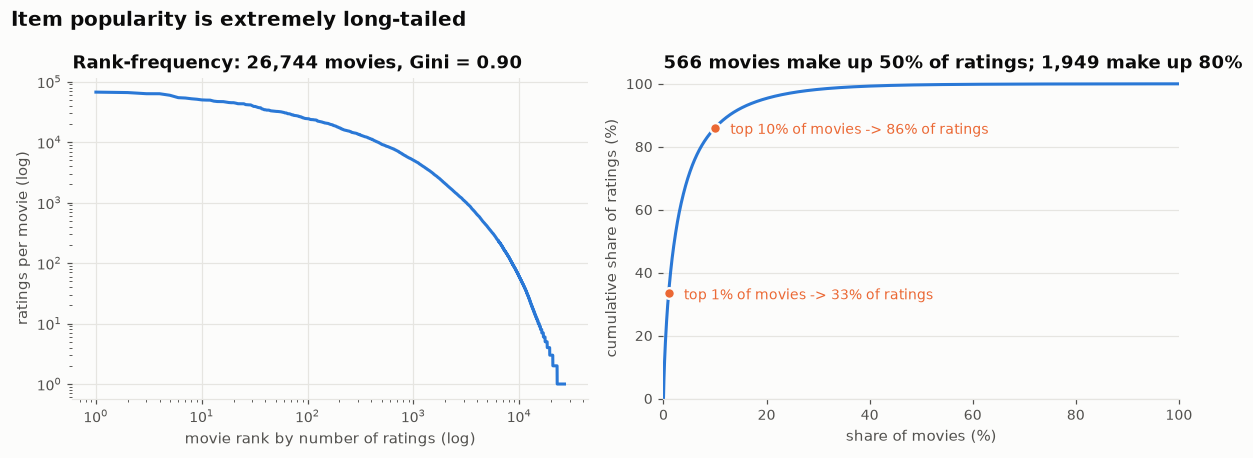

Gini of item popularity         : 0.903
top 1% / 10% of movies cover    : 33.5% / 86.1% of ratings
movies for 50% / 80% of ratings : 566 / 1,949
movies with a single rating     : 3,972
movies with < 5 ratings (any)   : 8,399  (the pipeline's single-pass item filter at 5 counts positives only, so it is stricter)


In [7]:
counts = np.sort(per_item["n"].to_numpy())[::-1].astype(np.float64)
ranks = np.arange(1, counts.size + 1)
cum_share = np.cumsum(counts) / counts.sum()
item_share = ranks / counts.size

def coverage(frac_items: float) -> float:
    k = max(1, int(round(frac_items * counts.size)))
    return cum_share[k - 1]

def items_for_share(target: float) -> int:
    return int(np.searchsorted(cum_share, target) + 1)

gini = 1 - 2 * np.trapezoid(np.cumsum(counts[::-1]) / counts.sum(), dx=1 / counts.size)
top1, top10 = coverage(0.01), coverage(0.10)
n50, n80 = items_for_share(0.5), items_for_share(0.8)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
ax1.plot(ranks, counts, color=C["blue"], linewidth=2)
ax1.set_xscale("log"); ax1.set_yscale("log")
ax1.set_xlabel("movie rank by number of ratings (log)")
ax1.set_ylabel("ratings per movie (log)")
ax1.set_title(f"Rank-frequency: {counts.size:,} movies, Gini = {gini:.2f}")
ax1.grid(True, axis="both")

ax2.plot(item_share * 100, cum_share * 100, color=C["blue"], linewidth=2)
for frac, cov in [(0.01, top1), (0.10, top10)]:
    ax2.plot([frac * 100], [cov * 100], marker="o", markersize=7, color=C["orange"], markeredgecolor=C["surface"], markeredgewidth=1.5)
    ax2.annotate(f"top {frac:.0%} of movies -> {cov:.0%} of ratings", (frac * 100, cov * 100),
                 xytext=(10, -4), textcoords="offset points", color=C["orange"], fontsize=9)
ax2.set_xlabel("share of movies (%)")
ax2.set_ylabel("cumulative share of ratings (%)")
ax2.set_title(f"{n50:,} movies make up 50% of ratings; {n80:,} make up 80%")
ax2.set_xlim(0, 100); ax2.set_ylim(0, 102)
fig.suptitle("Item popularity is extremely long-tailed", x=0.01, ha="left", fontsize=13, fontweight="bold", color=C["ink"])
fig.tight_layout()
fig.savefig(FIG_DIR / "03_item_popularity_longtail.png", bbox_inches="tight")
plt.show()

print(f"Gini of item popularity         : {gini:.3f}")
print(f"top 1% / 10% of movies cover    : {top1:.1%} / {top10:.1%} of ratings")
print(f"movies for 50% / 80% of ratings : {n50:,} / {n80:,}")
print(f"movies with a single rating     : {(counts == 1).sum():,}")
print(f"movies with < 5 ratings (any)   : {(counts < 5).sum():,}  (the pipeline's single-pass item filter at {cfg.min_item_interactions} counts positives only, so it is stricter)")

## 6. Genres and release years (DuckDB over Polars frames; Plot 4)

DuckDB queries Polars DataFrames in place (replacement scans), which keeps the analytical SQL
readable. Genre volume is weighted by *ratings*, not by movie count — that is what the item tower
sees during training.

In [8]:
# per-movie rating count + mean rating (26,744 rows) joined to genres; explode in Polars on the small frame
movie_stats = per_item.join(ratings.group_by("movieId").agg(pl.col("rating").mean().alias("mean_rating")), on="movieId")
genre_rows = (
    movies.select("movieId", "year", "genres").join(movie_stats, on="movieId", how="inner")
    .with_columns(pl.when(pl.col("genres").list.len() == 0).then(pl.lit(["(no genres listed)"])).otherwise(pl.col("genres")).alias("genres"))
    .explode("genres", empty_as_null=False).rename({"genres": "genre"})
)

genre_volume = duckdb.sql('''
    SELECT genre,
           COUNT(*)                                   AS n_movies,
           CAST(SUM(n) AS BIGINT)                     AS n_ratings,
           ROUND(SUM(n * mean_rating) / SUM(n), 3)    AS weighted_mean_rating
    FROM genre_rows
    GROUP BY genre
    ORDER BY n_ratings DESC
''').pl()
print(genre_volume)

decade_volume = duckdb.sql('''
    SELECT (year // 10) * 10 AS decade,
           COUNT(*)           AS n_movies,
           CAST(SUM(n) AS BIGINT) AS n_ratings,
           ROUND(SUM(n * mean_rating) / SUM(n), 3) AS weighted_mean_rating
    FROM movie_stats m
    JOIN (SELECT movieId, year FROM movies WHERE year IS NOT NULL) y USING (movieId)
    GROUP BY decade
    ORDER BY decade
''').pl()
print(decade_volume)
print(f"movies without a parseable release year: {movies['year'].null_count():,}")

shape: (20, 4)
┌────────────────────┬──────────┬───────────┬──────────────────────┐
│ genre              ┆ n_movies ┆ n_ratings ┆ weighted_mean_rating │
│ ---                ┆ ---      ┆ ---       ┆ ---                  │
│ str                ┆ i64      ┆ i64       ┆ f64                  │
╞════════════════════╪══════════╪═══════════╪══════════════════════╡
│ Drama              ┆ 13062    ┆ 8857853   ┆ 3.674                │
│ Comedy             ┆ 8232     ┆ 7502234   ┆ 3.426                │
│ Action             ┆ 3466     ┆ 5614208   ┆ 3.444                │
│ Thriller           ┆ 4129     ┆ 5313506   ┆ 3.507                │
│ Adventure          ┆ 2287     ┆ 4380351   ┆ 3.502                │
│ Romance            ┆ 4029     ┆ 3802002   ┆ 3.542                │
│ Crime              ┆ 2889     ┆ 3298335   ┆ 3.675                │
│ Sci-Fi             ┆ 1720     ┆ 3150141   ┆ 3.437                │
│ Fantasy            ┆ 1398     ┆ 2111403   ┆ 3.506                │
│ Children         

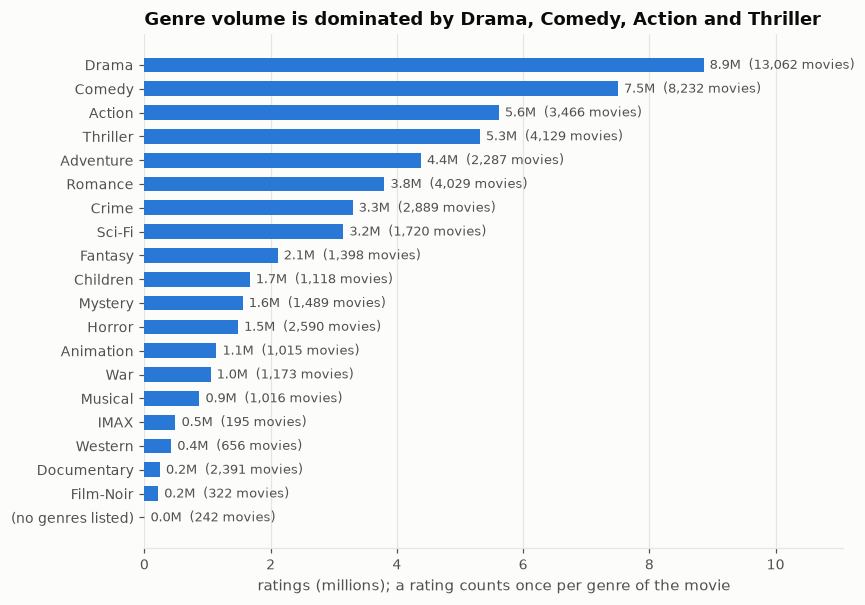

In [9]:
gv = genre_volume.sort("n_ratings")
fig, ax = plt.subplots(figsize=(8, 5.6))
ax.barh(gv["genre"], gv["n_ratings"] / 1e6, color=C["blue"], height=0.62, linewidth=0)
for y, (val, nm) in enumerate(zip(gv["n_ratings"], gv["n_movies"], strict=True)):
    ax.annotate(f"{val / 1e6:.1f}M  ({nm:,} movies)", (val / 1e6, y), xytext=(4, 0), textcoords="offset points",
                va="center", fontsize=8.5, color=C["ink2"])
ax.grid(True, axis="x"); ax.grid(False, axis="y")
ax.set_xlabel("ratings (millions); a rating counts once per genre of the movie")
ax.set_title("Genre volume is dominated by Drama, Comedy, Action and Thriller")
ax.margins(x=0.25)
fig.tight_layout()
fig.savefig(FIG_DIR / "04_genre_distribution.png", bbox_inches="tight")
plt.show()

## 7. Tags

Free-text tags are sparse (less than 3% of ratings have a tag) but cover a meaningful share of the
catalogue. User tags feed the BM25 index (the lexical baseline and the grounding step for LLM query
expansions); the optional BGE-M3 item text is built from titles, genres and the top genome tags.

In [10]:
tag_norm = tags.with_columns(pl.col("tag").str.to_lowercase().str.strip_chars().alias("tag_norm"))
movies_with_tag = tag_norm["movieId"].n_unique()
tagged_and_rated = tag_norm.join(ratings.select("movieId").unique(), on="movieId", how="semi")["movieId"].n_unique()
print(f"tag applications      : {tags.height:,}")
print(f"unique tags           : {tags['tag'].n_unique():,} raw / {tag_norm['tag_norm'].n_unique():,} lower-cased + trimmed")
print(f"users who tagged      : {tags['userId'].n_unique():,} ({tags['userId'].n_unique() / n_users:.1%} of users)")
print(f"movies with >= 1 tag  : {movies_with_tag:,} ({tagged_and_rated:,} of them rated: {tagged_and_rated / n_items_rated:.1%} of the {n_items_rated:,} rated movies)")
print(f"null tags             : {tags['tag'].null_count():,}")
tag_norm.group_by("tag_norm").len().sort("len", descending=True).head(15)

tag applications      : 465,564
unique tags           : 38,644 raw / 35,170 lower-cased + trimmed
users who tagged      : 7,801 (5.6% of users)
movies with >= 1 tag  : 19,545 (19,011 of them rated: 71.1% of the 26,744 rated movies)
null tags             : 0


tag_norm,len
str,u32
"""sci-fi""",3576
"""based on a book""",3307
"""atmospheric""",3169
"""comedy""",3078
"""action""",3068
"""nudity (topless)""",2646
"""surreal""",2528
"""twist ending""",2367
"""bd-r""",2334


## 8. Preprocessing + leave-one-out split -> parquet

The pipeline (`shopsage_rec.data.pipeline.run_prepare`) is the same code path as
`shopsage prepare`:

1. keep every raw rating in `ratings.parquet` (low ratings are explicit negatives for the ranker);
2. positives = rating >= 4.0; drop movies with < 5 positives, then users with < 5 positives;
3. contiguous `user_idx` / `item_idx` for the embedding tables (`mappings/`);
4. per user, by timestamp: newest positive -> **test**, second newest -> **val**, rest -> **train**;
   same-second ties are broken by a seeded SplitMix64 hash of the raw (userId, movieId), computed
   in numpy so it is independent of the Polars version and never favours high or low ids.

In [11]:
print(cfg.model_dump_json(indent=2))
report = run_prepare(cfg)
print()
print(report.summary())

{
  "dataset": "movielens-20m",
  "raw_dir": "/Users/zy/Project/new_sys/projects/shopsage-recommender/data/raw/ml-20m",
  "processed_dir": "/Users/zy/Project/new_sys/projects/shopsage-recommender/data/processed",
  "min_rating": 4.0,
  "min_item_interactions": 5,
  "min_user_interactions": 5,
  "split": {
    "strategy": "leave_one_out",
    "seed": 42
  }
}



prepared /Users/zy/Project/new_sys/projects/shopsage-recommender/data/processed
  raw ratings     :   20,000,263
  movies / tags   :       27,278 / 465,564
  users / items   :      136,674 / 13,681 (after filtering)
  train/val/test  :    9,704,107 / 136,674 / 136,674
  density         :     0.53360%
  boundary ties   :       20,580 users (test/val same second); 33,053 at either boundary
  cold test items :            0
  split sha256    : 5fa6cbe8f702...
  elapsed         :         2.3s


In [12]:
SPLITS = cfg.processed_dir / "splits"
meta = json.loads((SPLITS / "meta.json").read_text())

# DuckDB straight over the parquet files — the same thing a downstream job would do.
split_sizes = duckdb.sql(f'''
    SELECT 'train' AS split, COUNT(*) AS rows, COUNT(DISTINCT user_idx) AS users, COUNT(DISTINCT item_idx) AS items
    FROM read_parquet('{SPLITS / "train.parquet"}')
    UNION ALL
    SELECT 'val', COUNT(*), COUNT(DISTINCT user_idx), COUNT(DISTINCT item_idx) FROM read_parquet('{SPLITS / "val.parquet"}')
    UNION ALL
    SELECT 'test', COUNT(*), COUNT(DISTINCT user_idx), COUNT(DISTINCT item_idx) FROM read_parquet('{SPLITS / "test.parquet"}')
''').pl()
print(split_sizes)

train = pl.read_parquet(SPLITS / "train.parquet")
val = pl.read_parquet(SPLITS / "val.parquet")
test = pl.read_parquet(SPLITS / "test.parquet")

# sanity checks (the unit tests cover these on synthetic data; here on the real split)
assert test.height == val.height == meta["n_users"]
assert test["user_idx"].n_unique() == test.height
chk = (
    test.select("user_idx", pl.col("timestamp").alias("t_test"))
    .join(val.select("user_idx", pl.col("timestamp").alias("t_val")), on="user_idx")
    .join(train.group_by("user_idx").agg(pl.col("timestamp").max().alias("t_train_max")), on="user_idx")
)
assert (chk["t_test"] >= chk["t_val"]).all() and (chk["t_val"] >= chk["t_train_max"]).all()
assert pl.concat([train, val, test]).select("user_idx", "item_idx").n_unique() == meta["n_interactions"]
print("sanity checks passed")

print(json.dumps({k: meta[k] for k in (
    "n_users", "n_items", "n_interactions", "n_train", "n_val", "n_test", "density",
    "users_with_boundary_tie", "boundary_tie_fraction", "users_with_val_train_tie",
    "users_with_any_boundary_tie", "any_boundary_tie_fraction", "cold_test_items", "cold_val_items",
    "split_sha256", "tie_break",
)}, indent=2))

shape: (3, 4)
┌───────┬─────────┬────────┬───────┐
│ split ┆ rows    ┆ users  ┆ items │
│ ---   ┆ ---     ┆ ---    ┆ ---   │
│ str   ┆ i64     ┆ i64    ┆ i64   │
╞═══════╪═════════╪════════╪═══════╡
│ train ┆ 9704107 ┆ 136674 ┆ 13681 │
│ val   ┆ 136674  ┆ 136674 ┆ 7936  │
│ test  ┆ 136674  ┆ 136674 ┆ 8357  │
└───────┴─────────┴────────┴───────┘


sanity checks passed
{
  "n_users": 136674,
  "n_items": 13681,
  "n_interactions": 9977455,
  "n_train": 9704107,
  "n_val": 136674,
  "n_test": 136674,
  "density": 0.005336002567077246,
  "users_with_boundary_tie": 20580,
  "boundary_tie_fraction": 0.1505772860968436,
  "users_with_val_train_tie": 21139,
  "users_with_any_boundary_tie": 33053,
  "any_boundary_tie_fraction": 0.2418382428259947,
  "cold_test_items": 0,
  "cold_val_items": 0,
  "split_sha256": "5fa6cbe8f7027e8c4724d592857a0c4134821b33eef982e98d849aa88898c22e",
  "tie_break": "splitmix64(((user << 32) | item) xor splitmix64(seed=42)); key from precomputed column 'tie_key'"
}


## 9. Take-aways for the modelling days

The numbers printed below are computed from this run; the qualitative conclusions hold for any
ML-20M run with this configuration.

In [13]:
kept_ratings = meta["n_interactions"] / n_ratings
kept_users = meta["n_users"] / n_users
kept_items = meta["n_items"] / n_items_rated
train_per_user = train.group_by("user_idx").len()["len"]

print(f"1. Positive set: {meta['n_interactions']:,} interactions ({kept_ratings:.1%} of ratings) over "
      f"{meta['n_users']:,} users ({kept_users:.1%}) and {meta['n_items']:,} items ({kept_items:.1%}).")
print(f"   -> embedding tables: users {meta['n_users']:,} x 128, items {meta['n_items']:,} x 128 "
      f"= {(meta['n_users'] + meta['n_items']) * 128 * 4 / 1e6:.0f} MB fp32 (tiny; VRAM is not the bottleneck).")
print(f"2. Train interactions per user: median {train_per_user.median():.0f}, p10 {train_per_user.quantile(0.1):.0f}, "
      f"p90 {train_per_user.quantile(0.9):.0f}. In-batch negatives drawn uniformly over interactions over-represent heavy users.")
print(f"3. Long tail: top 10% of movies = {top10:.0%} of ratings (Gini {gini:.2f}). In-batch negatives are already "
      f"popularity-weighted, so the logQ correction is needed, and uniformly sampled extra negatives (MNS) are what reaches "
      f"the tail; a popularity baseline must be reported alongside the two-tower.")
print(f"4. {meta['users_with_boundary_tie']:,} users ({meta['boundary_tie_fraction']:.1%}) have test and val in the same second and "
      f"{meta['users_with_any_boundary_tie']:,} ({meta['any_boundary_tie_fraction']:.1%}) have a tie at either boundary: for most users the "
      f"'most recent' item is just the last one rated in a sign-up session, so the seeded tie-break is part of the protocol "
      f"and 'next-movie prediction' is the wrong framing (split digest {meta['split_sha256'][:12]}).")
if meta["cold_test_items"] == 0:
    print("5. Every test item also appears in train (0 cold test items in this run; the single-pass filter does not guarantee "
          "it), so Recall@K has no cold-item ceiling here; cold-start for genuinely new movies remains a limitation that an "
          "item-side OOV row would be needed to address.")
else:
    print(f"5. {meta['cold_test_items']:,} test items never appear in train: unreachable for an id-only retriever; they cap Recall@K "
          f"and motivate the genre/year/text features in the item tower.")
print(f"6. Each user contributes exactly one test item, so Recall@50 == HitRate@50 under this protocol and HR@K is "
      f"reported; the protocol decision (leave-one-out vs the Liang hold-out, D-001) is documented in docs/design.md.")

1. Positive set: 9,977,455 interactions (49.9% of ratings) over 136,674 users (98.7%) and 13,681 items (51.2%).
   -> embedding tables: users 136,674 x 128, items 13,681 x 128 = 77 MB fp32 (tiny; VRAM is not the bottleneck).
2. Train interactions per user: median 36, p10 10, p90 169. In-batch negatives drawn uniformly over interactions over-represent heavy users.
3. Long tail: top 10% of movies = 86% of ratings (Gini 0.90). In-batch negatives are already popularity-weighted, so the logQ correction is needed, and uniformly sampled extra negatives (MNS) are what reaches the tail; a popularity baseline must be reported alongside the two-tower.
4. 20,580 users (15.1%) have test and val in the same second and 33,053 (24.2%) have a tie at either boundary: for most users the 'most recent' item is just the last one rated in a sign-up session, so the seeded tie-break is part of the protocol and 'next-movie prediction' is the wrong framing (split digest 5fa6cbe8f702).
5. Every test item also app